<a href="https://colab.research.google.com/github/Katysssha/predictive-analysis/blob/main/practice1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practice #1. "Trend analysis"

In [9]:
!git clone https://github.com/klymya/ts_cource_practice.git
%cd ts_cource_practice/notebooks

Cloning into 'ts_cource_practice'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 53 (delta 21), reused 45 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 295.42 KiB | 3.69 MiB/s, done.
Resolving deltas: 100% (21/21), done.
/content/ts_cource_practice/notebooks


Smooth a series, then pull its trend out.

Fill in the cells tagged `graded`. They are marked and graded automatically, so
keep every function name and signature exactly as given. Untagged cells are
yours to change.

In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose

# DATA_DIR is injected when the grader imports this notebook; when you run the
# notebook yourself it falls back to ../data relative to this file.
def find_data_dir():
    """The repo's data/ directory, wherever the kernel happens to start."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "data" / "airline-passengers.csv").exists():
            return folder / "data"
    raise FileNotFoundError("data/ not found - run this notebook inside the repo")


DATA_DIR = globals().get("DATA_DIR", find_data_dir())

## 0. Data reading and visualization

`opsd_germany_daily.csv` has four columns. `Wind` and `Solar` are empty
before 2012, so a bare `df.dropna()` also drops six years of good `Consumption`.
Select your two columns first, then drop.

In [11]:
def load_series(path, time_col, value_col):
    """Read a CSV into a float Series named "y" on a DatetimeIndex."""
    df = pd.read_csv(path, usecols=[time_col, value_col])
    df = df.rename(columns={time_col: 'ds', value_col: 'y'})
    df['ds'] = pd.to_datetime(df['ds'])
    df = df.dropna()
    df = df.set_index('ds')
    return df['y'].astype(float)

In [12]:
series = load_series(DATA_DIR / "opsd_germany_daily.csv", "Date", "Consumption")
print(f"{len(series)} points from {series.index.min():%Y-%m-%d} "
      f"to {series.index.max():%Y-%m-%d}")
series.head()

4383 points from 2006-01-01 to 2017-12-31


,y
ds,
2006-01-01,1069.184
2006-01-02,1380.521
2006-01-03,1442.533
2006-01-04,1457.217
2006-01-05,1477.131


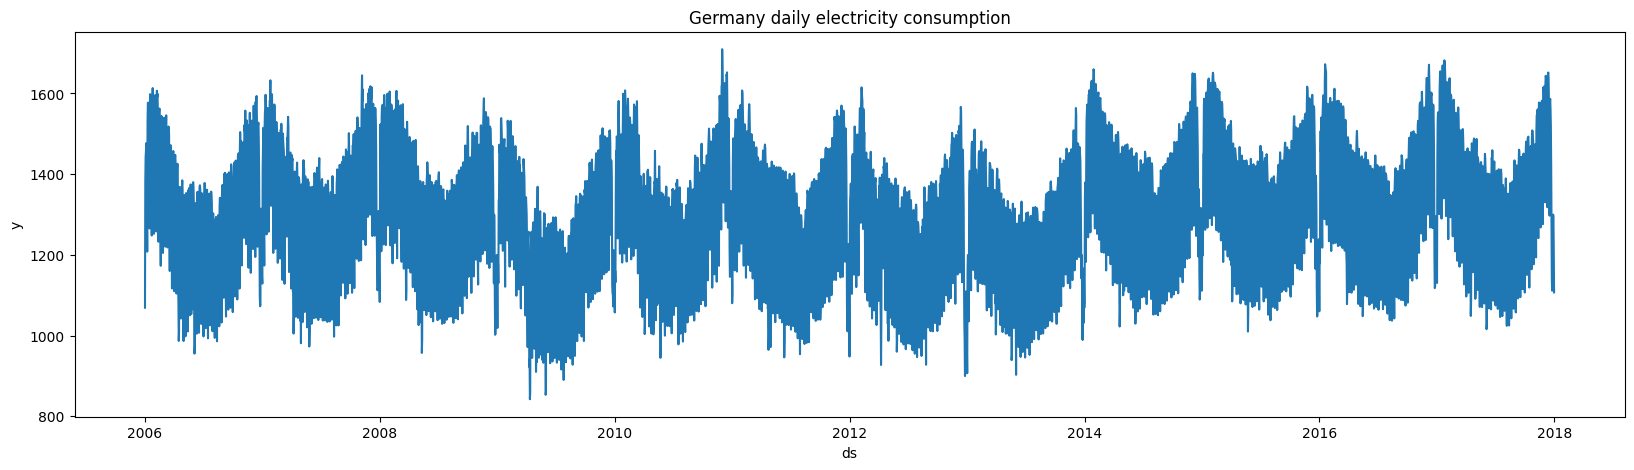

In [13]:
plt.figure(figsize=(20, 5))
plt.plot(series)
plt.ylabel("y")
plt.xlabel("ds")
plt.title("Germany daily electricity consumption");

## 1. Timeseries smoothing

### 1.1 Moving average

#### Centered moving average
$$x[t] = \frac{x[t - \lfloor n/2 \rfloor] + \ldots + x[t] + \ldots + x[t + \lfloor n/2 \rfloor]}{n}$$

#### Trailing moving average
$$x[t] = \frac{x[t - n + 1] + \ldots + x[t - 1] + x[t]}{n}$$

where $n$ is the window size. Only the trailing average is usable for
forecasting: the centred one reads values from the future.

In [18]:
def centered_moving_average(series, window):
    """Window centred on each point."""
    return series.rolling(window=window, center=True).mean()

def trailing_moving_average(series, window):
    """Window ending at each point."""
    return series.rolling(window=window).mean()

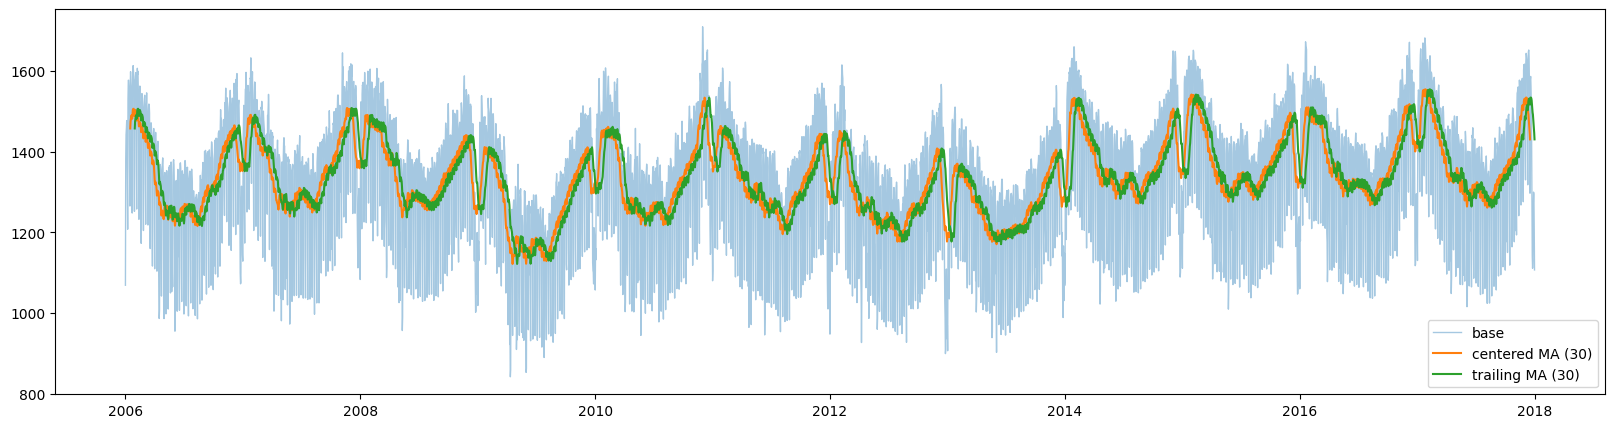

In [19]:
plt.figure(figsize=(20, 5))
plt.plot(series, linewidth=1, alpha=0.4, label="base")
plt.plot(centered_moving_average(series, 30), label="centered MA (30)")
plt.plot(trailing_moving_average(series, 30), label="trailing MA (30)")
plt.legend();

Smooth the data with several window sizes and compare.

**Question.** How does the window size change the smoothed series, and why is
the trailing average shifted to the right relative to the centred one?

Answer: A larger window size makes the series smoother by averaging out short-term fluctuations, but it becomes less responsive to recent changes. The trailing average is shifted to the right because it calculates the mean using only past data (ending at point $t$), whereas the centered average places the result exactly in the middle of the window by using both past and future data.

### 1.2 Exponential smoothing

The two libraries agree to floating-point precision — but only with the
right arguments.

- `ewm(alpha=a)` defaults to `adjust=True`: a renormalised weighted average, not
  the textbook recursion. It does **not** match statsmodels.
- `adjust=False` gives exactly `s[0] = x[0]`, `s[t] = a·x[t] + (1-a)·s[t-1]`.

Implement both. The assertion below must pass.

In [27]:
def exponential_smoothing(series, alpha):
    """SES via pandas: s[0] = x[0], s[t] = a*x[t] + (1-a)*s[t-1]."""
    return series.ewm(alpha=alpha, adjust=False).mean()

def exponential_smoothing_statsmodels(series, alpha):
    """Same recursion via statsmodels; return the level as a Series."""
    model = SimpleExpSmoothing(series, initialization_method="known", initial_level=series.iloc[0])
    return model.fit(smoothing_level=alpha, optimized=False).level

In [28]:
pandas_smoothed = exponential_smoothing(series, 0.3)
statsm_smoothed = exponential_smoothing_statsmodels(series, 0.3)
largest_gap = (pandas_smoothed - statsm_smoothed).abs().max()
print(f"max |pandas - statsmodels| = {largest_gap:.3e}")
assert largest_gap < 1e-8, "the two implementations must agree"

max |pandas - statsmodels| = 0.000e+00


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


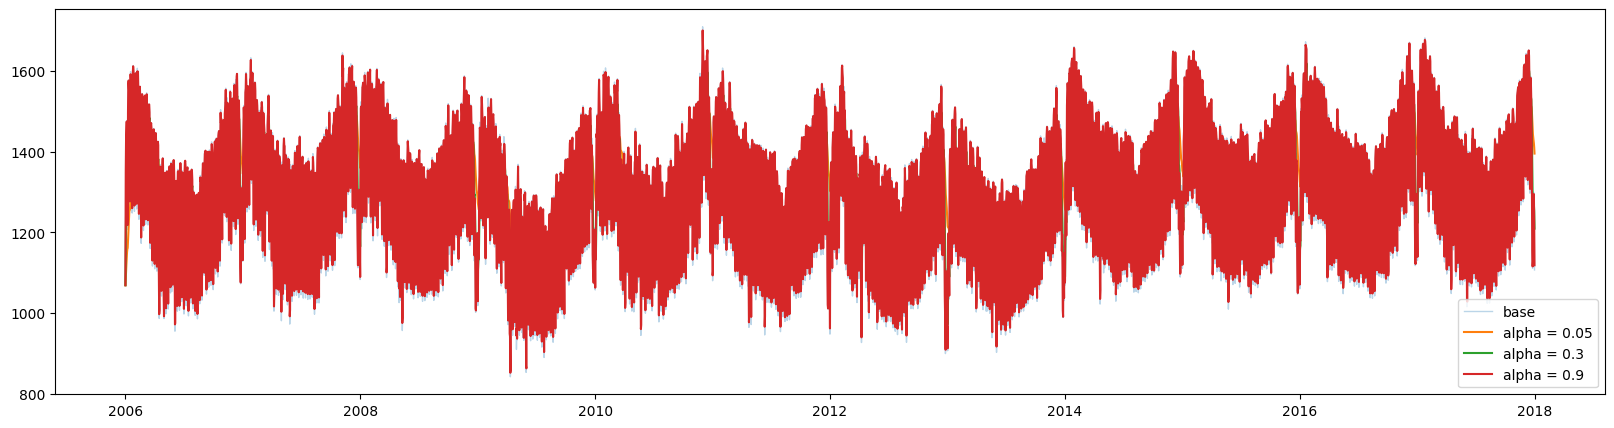

In [29]:
plt.figure(figsize=(20, 5))
plt.plot(series, linewidth=1, alpha=0.3, label="base")
for a in (0.05, 0.3, 0.9):
    plt.plot(exponential_smoothing(series, a), label=f"alpha = {a}")
plt.legend();

**Question.** What does alpha do to the smoothed series, and what
happens in the limits alpha -> 0 and alpha -> 1?

Answer: Alpha determines how much weight is given to the most recent observation. As $\alpha \to 1$, the smoothed series closely follows the original noisy data (high responsiveness). As $\alpha \to 0$, the series becomes very smooth and flat, ignoring recent changes and relying heavily on the historical average.

### 1.3 Double exponential smoothing

Holt's method adds a trend component: a level `l[t]` smoothed by alpha
and a slope `b[t]` smoothed by beta.

In [30]:
def double_exponential_smoothing(series, alpha, beta, trend="add"):
    """Holt's linear trend smoothing; return the fitted level as a Series."""
    model = ExponentialSmoothing(series, trend=trend, initialization_method="estimated")
    return model.fit(smoothing_level=alpha, smoothing_trend=beta).fittedvalues

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


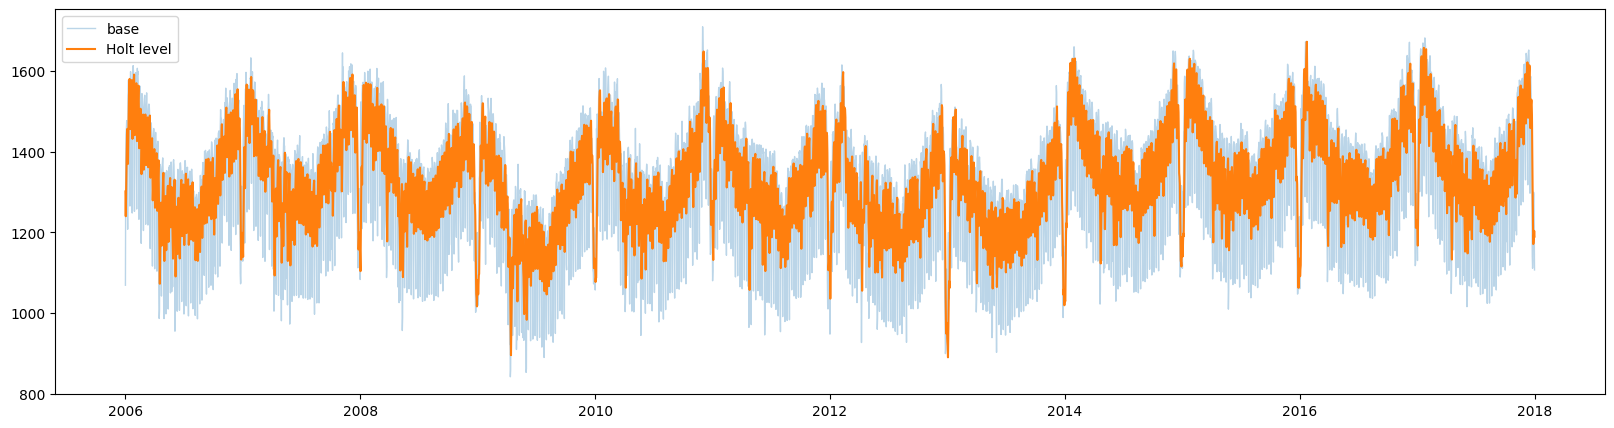

In [31]:
plt.figure(figsize=(20, 5))
plt.plot(series, linewidth=1, alpha=0.3, label="base")
plt.plot(double_exponential_smoothing(series, 0.3, 0.1), label="Holt level")
plt.legend();

Try several alpha/beta pairs and both trend types (`"add"`, `"mul"`).

**Questions.** What does beta control? Are alpha and beta related?

statsmodels may raise `ConvergenceWarning` here. Don't silence it — it means the
fit never settled, and the numbers below it are not trustworthy.

Answer: Beta controls the smoothing of the trend component, determining how quickly the model adapts to changes in the slope. Alpha and beta are related because the trend estimate (smoothed by beta) is calculated based on the difference between successive level estimates (which are smoothed by alpha).

## 2. Trend extraction

### 2.1 Linear regression

In [32]:
def linear_trend(series):
    """Least-squares straight line through the series, as a Series."""
    X = np.arange(len(series)).reshape(-1, 1)
    model = LinearRegression().fit(X, series)
    return pd.Series(model.predict(X), index=series.index)

def decomposition_trend(series, period, model="additive"):
    """Trend component from seasonal_decompose.
    Keep the NaNs at both ends: that is where a centred window does not fit.
    """
    return seasonal_decompose(series, model=model, period=period).trend

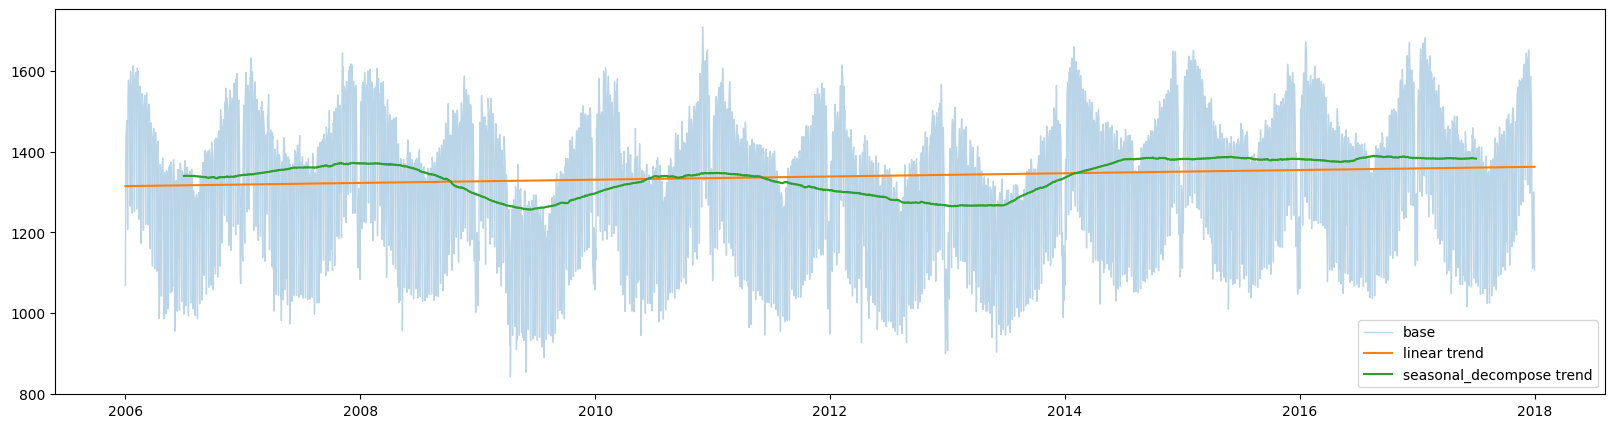

In [33]:
trend_line = linear_trend(series)
trend_decomposed = decomposition_trend(series, period=365)

plt.figure(figsize=(20, 5))
plt.plot(series, linewidth=1, alpha=0.3, label="base")
plt.plot(trend_line, label="linear trend")
plt.plot(trend_decomposed, label="seasonal_decompose trend")
plt.legend();

### 2.2 Comparing the two trends

`seasonal_decompose(period=365)` uses a centred moving average, so the first and
last ~182 days have no value. Compare only where both trends are defined.

In [34]:
both_defined = trend_decomposed.notna()
error = mean_squared_error(trend_decomposed[both_defined], trend_line[both_defined])
print(f"points compared: {int(both_defined.sum())} of {len(series)}")
print(f"MSE between the two trend estimates: {error:.2f}")

points compared: 4019 of 4383
MSE between the two trend estimates: 1491.74


**Question.** Repeat the comparison on a series you smoothed first. Does
smoothing change the linear trend? Why, or why not?

Answer: Smoothing does not significantly change the overall linear trend. It only averages out short-term noise and seasonal variations, but the fundamental long-term trajectory (the slope and intercept of the linear regression line) remains largely the same because the overall distribution of data points is preserved